# Exploratory data analysis

This notebook only draws pictures of the cleaned table.
It does not scale columns, split the rows, train a model, or change the uneven purchase split.

Every chart is saved at 150 dpi under `images/` and uses the values as they are stored.
A log scale, where it appears, is for the picture only.


### Load the cleaned file

`read_csv` turns the four code columns back into numbers. We cast them to text immediately.
`month_order` is the same Jan-to-Dec list used in the cleaning notebook. January and April are in that list and are absent from the file.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

np.random.seed(42)
sns.set_theme(style="whitegrid")

if Path("data/processed/cleaned_shoppers.csv").exists():
    cleaned_path = Path("data/processed/cleaned_shoppers.csv")
    image_dir = Path("images")
else:
    cleaned_path = Path("../data/processed/cleaned_shoppers.csv")
    image_dir = Path("../images")

image_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(cleaned_path)
code_columns = ["OperatingSystems", "Browser", "Region", "TrafficType"]
for column in code_columns:
    df[column] = df[column].astype(str)

month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]
present_months = [month for month in month_order if (df["Month"] == month).any()]
df["Month"] = pd.Categorical(df["Month"], categories=present_months, ordered=True)

assert len(df) == 12205
assert int(df.isna().sum().sum()) == 0
print("Rows:", len(df))
print("Missing cells:", int(df.isna().sum().sum()))
print("Months in calendar order:", present_months)
print("Absent from month_order:", [month for month in month_order if month not in present_months])


def save_and_show(fig, name):
    # name is the file stem after 02_.
    path = image_dir / f"02_{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path)
    plt.show()


Matplotlib is building the font cache; this may take a moment.


Rows: 12205
Missing cells: 0
Months in calendar order: ['Feb', 'Mar', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
Absent from month_order: ['Jan', 'Apr']


The file has **12,205** rows and **0** missing cells. The months present, in calendar order, are Feb through Dec except April. January and April are absent.


### 1. Did the visitor buy?

`Revenue` is 1 for a purchase and 0 otherwise. This chart only counts. It does not rebalance the classes.


Revenue
0    10297
1     1908
Revenue
0    84.37
1    15.63


Saved: ../images/02_revenue_counts.png


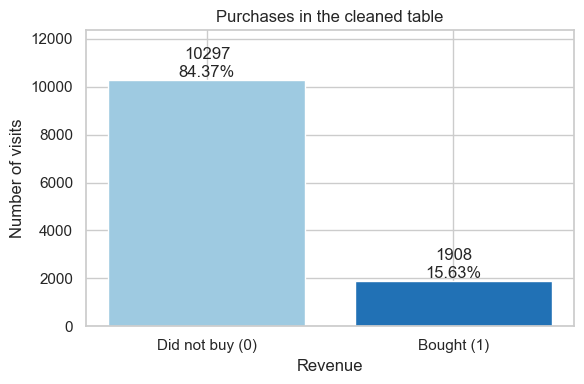

In [2]:
revenue_counts = df["Revenue"].value_counts().sort_index()
revenue_percent = 100 * revenue_counts / len(df)
print(revenue_counts.to_string())
print(revenue_percent.round(2).to_string())

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["Did not buy (0)", "Bought (1)"]
bars = ax.bar(labels, revenue_counts.values, color=["#9ecae1", "#2171b5"])
for bar, count, percent in zip(bars, revenue_counts.values, revenue_percent.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(count)}\n{percent:.2f}%",
        ha="center",
        va="bottom",
    )
ax.set_ylabel("Number of visits")
ax.set_xlabel("Revenue")
ax.set_title("Purchases in the cleaned table")
ax.set_ylim(0, revenue_counts.max() * 1.2)
fig.tight_layout()
save_and_show(fig, "revenue_counts")


Of the **12,205** visits, **1,908** bought (**15.63%**) and **10,297** did not (**84.37%**). The classes stay uneven. This notebook does not change that.


### 2. Histograms of the numeric columns

The title of each panel is the percent of zeros. A log scale on the count axis is display only, and only where the raw counts would hide the tail. The table is not changed.


Percent of zeros:
  Administrative: 46.24%
  Administrative_Duration: 47.34%
  Informational: 78.44%
  Informational_Duration: 80.29%
  ProductRelated: 0.31%
  ProductRelated_Duration: 5.16%
  BounceRates: 45.21%
  ExitRates: 0.62%
  PageValues: 77.63%
  SpecialDay: 89.77%
  Weekend: 76.58%
  Revenue: 84.37%


Saved: ../images/02_histograms_numeric.png


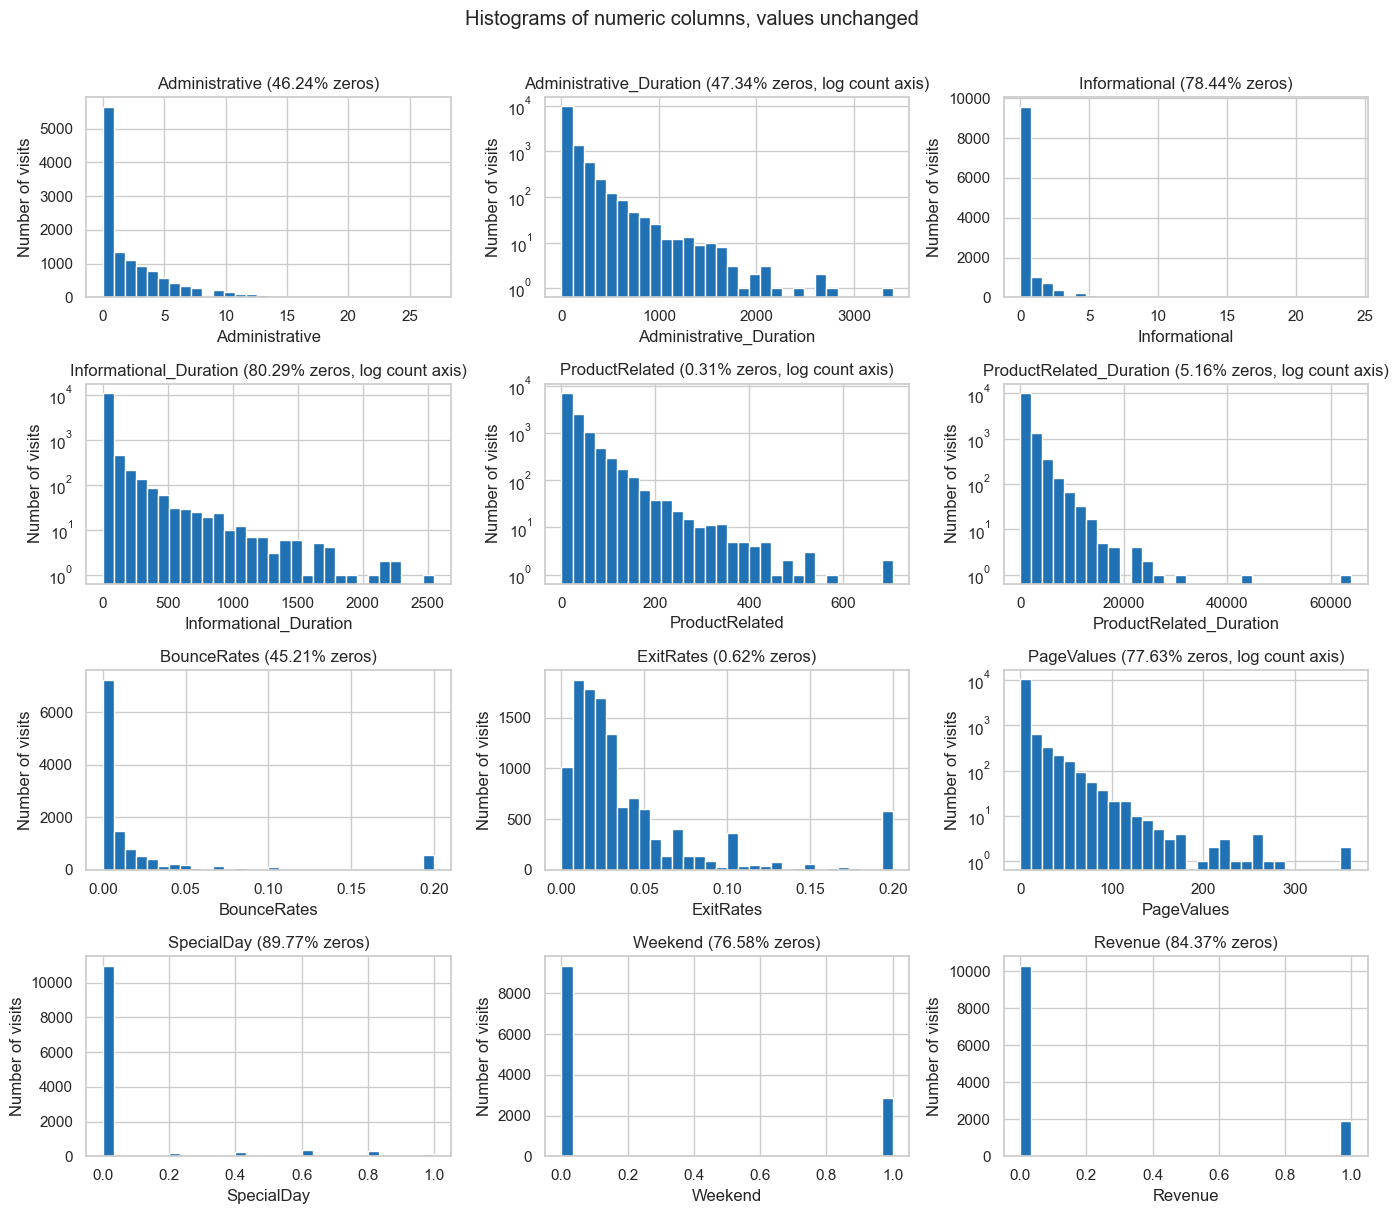

In [3]:
number_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "Weekend",
    "Revenue",
]
# These columns run into the hundreds or thousands, so a log count axis shows the tail.
log_count_columns = {
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "PageValues",
}

print("Percent of zeros:")
for column in number_columns:
    percent_zero = 100 * (df[column] == 0).mean()
    print(f"  {column}: {percent_zero:.2f}%")

fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for ax, column in zip(axes.ravel(), number_columns):
    percent_zero = 100 * (df[column] == 0).mean()
    ax.hist(df[column], bins=30, color="#2171b5")
    if column in log_count_columns:
        ax.set_yscale("log")
        scale_note = ", log count axis"
    else:
        scale_note = ""
    ax.set_title(f"{column} ({percent_zero:.2f}% zeros{scale_note})")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of visits")
fig.suptitle("Histograms of numeric columns, values unchanged", y=1.01)
fig.tight_layout()
save_and_show(fig, "histograms_numeric")


`SpecialDay` is 0 on **89.77%** of rows, `Informational_Duration` on **80.29%**, and `PageValues` on **77.63%**. `ProductRelated` is 0 on only **0.31%** of rows, and `ExitRates` on **0.62%**. `Revenue` is 0 on **84.37%** of rows, which is the same 10,297 non-buyers as the bar chart.


### 3. Boxplots

Each numeric column gets its own raw scale, so a long duration does not flatten the other boxes.
The second figure compares buyers and non-buyers on the columns with a real tail or a strong link to purchase. `log1p` on an axis is display only.


Saved: ../images/02_boxplots_numeric.png


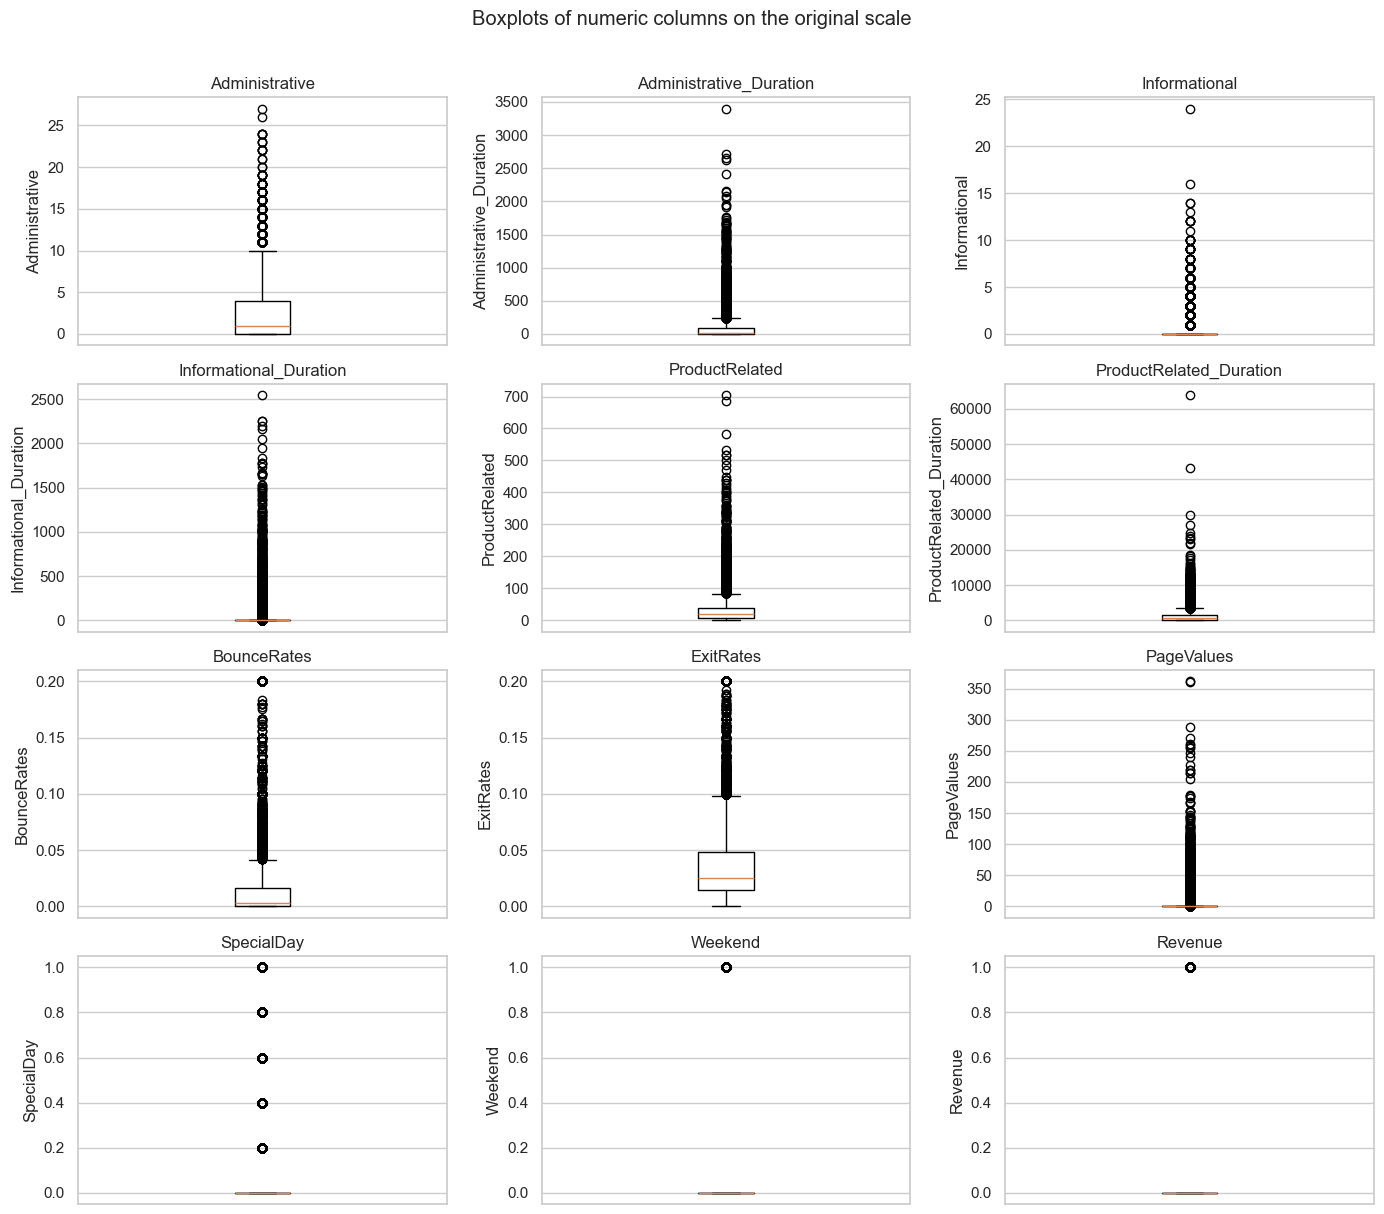

Median by Revenue. This print does not change the table:
  Administrative_Duration, Revenue 0: 0.00
  Administrative_Duration, Revenue 1: 52.37
  ProductRelated, Revenue 0: 16.00
  ProductRelated, Revenue 1: 29.00
  ProductRelated_Duration, Revenue 0: 526.00
  ProductRelated_Duration, Revenue 1: 1109.91
  PageValues, Revenue 0: 0.00
  PageValues, Revenue 1: 16.76
  BounceRates, Revenue 0: 0.00
  BounceRates, Revenue 1: 0.00
  ExitRates, Revenue 0: 0.03
  ExitRates, Revenue 1: 0.02


Saved: ../images/02_boxplots_by_revenue.png


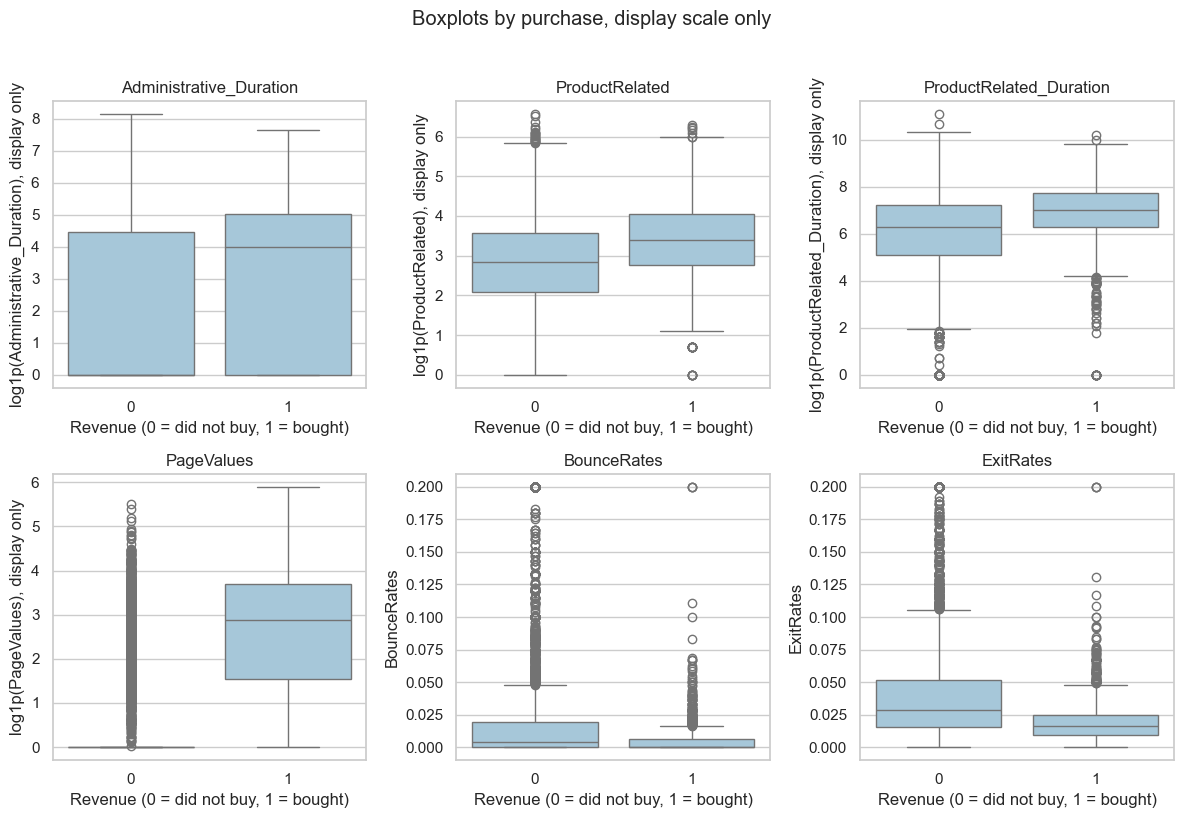

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for ax, column in zip(axes.ravel(), number_columns):
    ax.boxplot(df[column], vert=True, showfliers=True)
    ax.set_title(column)
    ax.set_ylabel(column)
    ax.set_xticks([])
    ax.set_xlabel("")
fig.suptitle("Boxplots of numeric columns on the original scale", y=1.01)
fig.tight_layout()
save_and_show(fig, "boxplots_numeric")

key_columns = [
    "Administrative_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "PageValues",
    "BounceRates",
    "ExitRates",
]
print("Median by Revenue. This print does not change the table:")
for column in key_columns:
    for revenue_value in [0, 1]:
        median_value = df.loc[df["Revenue"] == revenue_value, column].median()
        print(f"  {column}, Revenue {revenue_value}: {median_value:.2f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, column in zip(axes.ravel(), key_columns):
    # A copy used only for the axis. df itself is not replaced.
    if df[column].max() > 1:
        shown = np.log1p(df[column])
        ylabel = f"log1p({column}), display only"
    else:
        shown = df[column]
        ylabel = column
    plot_frame = pd.DataFrame({"Revenue": df["Revenue"].astype(str), "shown": shown})
    sns.boxplot(data=plot_frame, x="Revenue", y="shown", ax=ax, color="#9ecae1")
    ax.set_title(column)
    ax.set_xlabel("Revenue (0 = did not buy, 1 = bought)")
    ax.set_ylabel(ylabel)
fig.suptitle("Boxplots by purchase, display scale only", y=1.02)
fig.tight_layout()
save_and_show(fig, "boxplots_by_revenue")


Buyers have a higher median `ProductRelated_Duration` (**1,109.91** versus **526.00**) and a higher median `PageValues` (**16.76** versus **0**). `BounceRates` has median **0** in both groups, because **45.21%** of all rows are already 0. Nothing was capped or deleted.
